In [37]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc
from sklearn.preprocessing import StandardScaler

In [2]:
# каталог с ноутбуками и корень проекта
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BACKEND = ROOT / "backend"
if str(BACKEND) not in sys.path:
    sys.path.insert(0, str(BACKEND))
from src.analytics import assess, guess_mapping, normalize, read_table
from src.analytics.quality import drop_duplicates, trim_incomplete_tail
from src.analytics.schema import AMOUNT, CUSTOMER_ID, ORDER_DATE
# данные
DATA_PATH = ROOT / "data" / "raw" / "online_retail_II.xlsx"
raw = read_table(DATA_PATH)
source = "Online Retail II"
# распознавание колонок
mapping = guess_mapping(raw)

for canonical, column in mapping.as_dict().items():
    print(f"{canonical:<12} <- {column}")

if mapping.unmapped:
    print("\nНе распознано:", ", ".join(map(str, mapping.unmapped)))

assert mapping.is_valid, f"Не хватает колонок: {mapping.missing_required}"
# отчистка 
clean = normalize(raw, mapping)
clean, duplicates = drop_duplicates(clean)
clean, tail_trimmed = trim_incomplete_tail(clean)



order_date   <- InvoiceDate
customer_id  <- Customer ID
order_id     <- Invoice
quantity     <- Quantity
unit_price   <- Price

Не распознано: StockCode, Description, Country


In [3]:
CHURN_DAYS = 90
df = clean.copy()
df = df[df['amount'] > 0]
# разделяем данные на train и test
min_date = pd.to_datetime(df['order_date']).min()
split_date = min_date + pd.DateOffset(months=9)

train_df = df[pd.to_datetime(df['order_date']) < split_date].copy()
test_df = df[pd.to_datetime(df['order_date']) >= split_date].copy()

In [29]:
def create_dataset_for_slice(df, slice_date, churn_days=90):
    """
    Считает признаки строго по истории ДО slice_date.
    Считает таргет строго по окну [slice_date, slice_date + churn_days].
    """
    # История ДО момента среза T
    history = df[df['order_date'] < slice_date].copy()
    # Будущее окно для расчета оттока
    future = df[(df['order_date'] >= slice_date) & (df['order_date'] < slice_date + pd.Timedelta(days=churn_days))]
    
    if history.empty:
        return pd.DataFrame()
        
    # Максимальная дата в истории для расчета recency и tenure
    max_hist_date = history['order_date'].max()
    
    # Считаем базовые агрегаты RFM
    user_features = history.groupby('customer_id').agg(
        total_amount=('amount', 'sum'),
        order_count=('order_id', 'nunique'),
        first_order=('order_date', 'min'),
        last_order=('order_date', 'max'),
    ).reset_index()
    
    # Расчет Recency, Frequency, Monetary, Tenure
    user_features['recency'] = (slice_date - user_features['last_order']).dt.days
    user_features['tenure'] = (slice_date - user_features['first_order']).dt.days
    user_features['frequency'] = user_features['order_count']
    user_features['monetary'] = user_features['total_amount']
    
    # Динамика активности за 30 и 90 дней против базового уровня (всего tenure)
    # Сколько клиент тратил в среднем в день за всю историю жизни в системе
    user_features['base_daily_spend'] = user_features['total_amount'] / user_features['tenure'].clip(lower=1)
    
    # Траты за последние 30 и 90 дней до среза
    spend_30 = history[history['order_date'] >= slice_date - pd.Timedelta(days=30)].groupby('customer_id')['amount'].sum()
    spend_90 = history[history['order_date'] >= slice_date - pd.Timedelta(days=90)].groupby('customer_id')['amount'].sum()
    
    user_features['spend_30'] = user_features['customer_id'].map(spend_30).fillna(0)
    user_features['spend_90'] = user_features['customer_id'].map(spend_90).fillna(0)
    
    user_features['activity_dynamics_30'] = user_features['spend_30'] / 30 / user_features['base_daily_spend'].clip(lower=0.01)
    user_features['activity_dynamics_90'] = user_features['spend_90'] / 90 / user_features['base_daily_spend'].clip(lower=0.01)
    
    # Расчет межпокупочных интервалов
    # Сортируем историю по клиентам и датам для расчета разницы между покупками
    history_sorted = history.sort_values(['customer_id', 'order_date'])
    # Берём уникальные даты заказов для каждого клиента (интервалы между днями посещений)
    unique_orders = history_sorted.groupby(['customer_id', 'order_date']).size().reset_index()
    unique_orders['prev_order_date'] = unique_orders.groupby('customer_id')['order_date'].shift(1)
    unique_orders['interval'] = (unique_orders['order_date'] - unique_orders['prev_order_date']).dt.days
    
    intervals_stats = unique_orders.groupby('customer_id')['interval'].agg(
        mean_interval='mean',
        std_interval='std'
    ).reset_index()
    
    user_features = user_features.merge(intervals_stats, on='customer_id', how='left')
    user_features['std_interval'] = user_features['std_interval'].fillna(0)
    # Если покупка одна — средний интервал равен времени от покупки до среза (или tenure)
    user_features['mean_interval'] = user_features['mean_interval'].fillna(user_features['tenure'])
    
    # Отношение последнего интервала к среднему (главный сигнал)
    user_features['last_interval'] = user_features['recency']
    user_features['last_to_mean_interval_ratio'] = user_features['last_interval'] / user_features['mean_interval'].clip(lower=1)
    
    # Сезонность (компонент времени среза)
    user_features['slice_month'] = slice_date.month
    
    # Определение Таргета: 1 если нет покупок в будущие churn_days дней
    active_in_future = future['customer_id'].unique()
    user_features['target'] = (~user_features['customer_id'].isin(active_in_future)).astype(int)
    
    # Выделяем только нужные финальные признаки по ТЗ
    feature_cols = [
        'customer_id', 'recency', 'frequency', 'monetary', 'tenure',
        'mean_interval', 'std_interval', 'last_to_mean_interval_ratio',
        'activity_dynamics_30', 'activity_dynamics_90', 
        'slice_month', 'target'
    ]
    
    return user_features[feature_cols]

In [30]:
min_global_date = df['order_date'].min()
max_global_date = df['order_date'].max()

# Генерируем сетку исторических срезов с шагом в 30 дней
# Оставляем в конце запас размером в CHURN_DAYS для честного расчета тестового таргета
available_end_date = max_global_date - pd.Timedelta(days=CHURN_DAYS)
slice_dates = pd.date_range(start=min_global_date + pd.DateOffset(months=3), end=available_end_date, freq='30D')

print(f"Сгенерировано временных срезов для валидации: {len(slice_dates)}")
print(f"Даты срезов: {slice_dates.strftime('%Y-%m-%d').tolist()}\n")

# Разделяем срезы по времени (Валидация только по времени)
# Все срезы кроме последнего — в Train, самый поздний срез — в Тест (OOT)
train_slices = slice_dates[:-1]
test_slice = slice_dates[-1]

# Собираем TRAIN из нескольких срезов
train_datasets = []
for i, s_date in enumerate(train_slices):
    slice_df = create_dataset_for_slice(df, s_date, churn_days=CHURN_DAYS)
    if not slice_df.empty:
        slice_df['slice_id'] = i  # Идентификатор временного среза
        train_datasets.append(slice_df)

train_set = pd.concat(train_datasets, ignore_index=True)

# Собираем TEST (Out-of-Time срез)
test_set = create_dataset_for_slice(df, test_slice, churn_days=CHURN_DAYS)

Сгенерировано временных срезов для валидации: 7
Даты срезов: ['2010-03-01', '2010-03-31', '2010-04-30', '2010-05-30', '2010-06-29', '2010-07-29', '2010-08-28']



In [31]:
drop_cols = ['customer_id', 'target', 'slice_id']

X_train = train_set.drop(columns=drop_cols, errors='ignore')
y_train = train_set['target']

X_test = test_set.drop(columns=['customer_id', 'target'], errors='ignore')
y_test = test_set['target']

# Заполнение возможных NaN значений (для линейных моделей)
X_train_filled = X_train.fillna(0)
X_test_filled = X_test.fillna(0)

In [32]:
def calculate_lift_at_k(y_true, y_pred_proba, k=0.1):
    df_metrics = pd.DataFrame({"target": y_true, "proba": y_pred_proba})
    df_metrics = df_metrics.sort_values(by="proba", ascending=False).reset_index(drop=True)
    n_top = int(len(df_metrics) * k)
    if n_top == 0:
        return 0
    base_rate = df_metrics["target"].mean()
    if base_rate == 0:
        return 0
    top_rate = df_metrics["target"].head(n_top).mean()
    return top_rate / base_rate

In [33]:
def evaluate_model(y_true, y_pred_proba, model_name="Model"):
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    precision, recall, _ = precision_recall_curve(y_true, y_pred_proba)
    pr_auc = auc(recall, precision)
    lift_10 = calculate_lift_at_k(y_true, y_pred_proba, k=0.1)

    print(f"--- {model_name} (OOT-Тест на дату {test_slice.strftime('%Y-%m-%d')}) ---")
    print(f"ROC-AUC:  {roc_auc:.4f} | PR-AUC:   {pr_auc:.4f} | Lift@10%: {lift_10:.4f}\n")
    return {"ROC-AUC": roc_auc, "PR-AUC": pr_auc, "Lift@10%": lift_10}

In [34]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_filled)
X_test_scaled = scaler.transform(X_test_filled)

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_results = evaluate_model(y_test, lr_model.predict_proba(X_test_scaled)[:, 1], "Logistic Regression (Baseline)")

# МОДЕНА: LightGBM
lgb_model = LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=42, n_jobs=-1, verbose=-1)
lgb_model.fit(X_train_filled, y_train)
lgb_results = evaluate_model(y_test, lgb_model.predict_proba(X_test_filled)[:, 1], "LightGBM")


--- Logistic Regression (Baseline) (OOT-Тест на дату 2010-08-28) ---
ROC-AUC:  0.7255 | PR-AUC:   0.6102 | Lift@10%: 1.5922

--- LightGBM (OOT-Тест на дату 2010-08-28) ---
ROC-AUC:  0.7598 | PR-AUC:   0.6535 | Lift@10%: 1.7635



--- Калибровка модели ---
Результаты после калибровки:
--- Calibrated LightGBM (OOT-Тест на дату 2010-08-28) ---
ROC-AUC:  0.7507 | PR-AUC:   0.6445 | Lift@10%: 1.6921



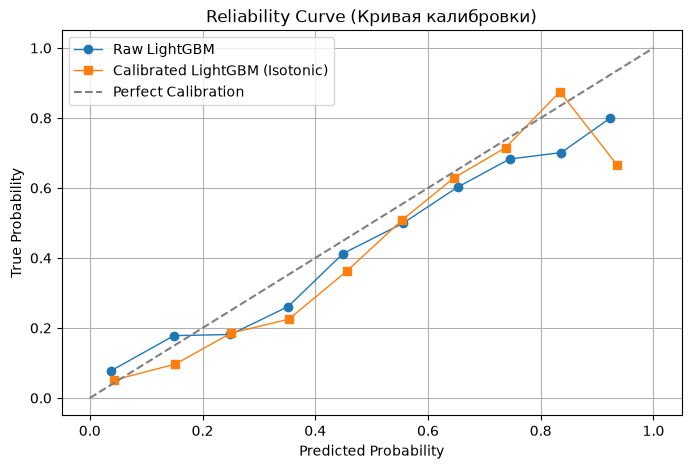

In [38]:
print("--- Калибровка модели ---")
# Базовая модель LightGBM
base_lgb = LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=42, n_jobs=-1, verbose=-1)

# Калибровка с помощью Изотонической регрессии поверх LightGBM
# Используем ensemble=False и cv=3, чтобы откалибровать вероятности без заглядывания в будущее теста
calibrated_lgb = CalibratedClassifierCV(estimator=base_lgb, method='isotonic', cv=3)
calibrated_lgb.fit(X_train_filled, y_train)

# Получаем вероятности базовой и калиброванной моделей на OOT-тесте
proba_uncalibrated = lgb_model.predict_proba(X_test_filled)[:, 1] # lgb_model из прошлого шага
proba_calibrated = calibrated_lgb.predict_proba(X_test_filled)[:, 1]

# Оцениваем качество калиброванной модели
print("Результаты после калибровки:")
calibrated_results = evaluate_model(y_test, proba_calibrated, "Calibrated LightGBM")

# Строим Reliability Curve (Кривую калибровки)
prob_true_uncal, prob_pred_uncal = calibration_curve(y_test, proba_uncalibrated, n_bins=10)
prob_true_cal, prob_pred_cal = calibration_curve(y_test, proba_calibrated, n_bins=10)

plt.figure(figsize=(8, 5))
plt.plot(prob_pred_uncal, prob_true_uncal, marker='o', linewidth=1, label='Raw LightGBM')
plt.plot(prob_pred_cal, prob_true_cal, marker='s', linewidth=1, label='Calibrated LightGBM (Isotonic)')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
plt.xlabel('Predicted Probability')
plt.ylabel('True Probability')
plt.title('Reliability Curve (Кривая калибровки)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print("--- Расчет SHAP values ---")
# Для расчета SHAP используем базовую модель 
# Так как изотоническая регрессия — это монотонное преобразование, важность признаков берем из деревянной модели
explainer = shap.TreeExplainer(lgb_model)
shap_values = explainer(X_test_filled)

# Функция генерации понятных бизнесу причин оттока
def generate_retention_insights(X_df, shap_values_obj, customer_ids, top_n=3):
    """
    Конвертирует SHAP values в текстовые бизнес-причины для менеджеров по удержанию.
    """
    insights = []
    # Извлекаем значения SHAP для класса 1 (отток)
    if len(shap_values_obj.values.shape) == 3:
        vals = shap_values_obj.values[:, :, 1]
    else:
        vals = shap_values_obj.values
        
    feature_names = X_df.columns
    
    for idx in range(len(X_df)):
        c_id = customer_ids.iloc[idx]
        row_features = X_df.iloc[idx]
        row_shap = vals[idx]
        
        # Сортируем признаки по их вкладу в ОТТОК (положительный SHAP увеличивает вероятность ухода)
        top_indices = np.argsort(row_shap)[::-1][:top_n]
        
        reasons = []
        for f_idx in top_indices:
            f_name = feature_names[f_idx]
            f_val = row_features[f_name]
            
            # Бизнес-переводчики для главных сигналов 
            if f_name == 'last_to_mean_interval_ratio' and f_val > 1.5:
                reasons.append(f"Молчит слишком долго: текущая пауза превышает норму в {f_val:.1f} раз")
            elif f_name == 'recency':
                reasons.append(f"Не покупал уже {int(f_val)} дней (критично для удержания)")
            elif f_name == 'activity_dynamics_30' and f_val < 0.5:
                reasons.append(f"Дропнул активность: траты за последние 30 дней упали ниже половины его базового уровня")
            elif f_name == 'activity_dynamics_90' and f_val < 0.7:
                reasons.append(f"Долговременный спад: активность за 90 дней сильно ниже нормы")
            elif f_name == 'mean_interval' and f_val > 60:
                reasons.append(f"В целом редкий клиент (средний интервал между покупками {int(f_val)} дней)")
            else:
                # Базовый вариант, если признак специфический
                direction = "высокое" if row_shap[f_idx] > 0 else "низкое"
                reasons.append(f"Фактор '{f_name}' имеет неоптимальное значение ({f_val:.2f})")
                
        insights.append({
            "customer_id": c_id,
            "reason_1": reasons[0] if len(reasons) > 0 else "Нет выраженных аномалий",
            "reason_2": reasons[1] if len(reasons) > 1 else "-",
            "reason_3": reasons[2] if len(reasons) > 2 else "-"
        })
        
    return pd.DataFrame(insights)

# Собираем витрину действий для бизнеса (Actionable CRM Dataset)
crm_action_df = pd.DataFrame({
    "customer_id": test_set['customer_id'],
    "churn_probability": proba_calibrated # 
})

# Генерируем текстовые инсайты по SHAP
shap_text_reasons = generate_retention_insights(X_test_filled, shap_values, test_set['customer_id'])

# Склеиваем скоры и причины в единую CRM-панель
crm_action_df = crm_action_df.merge(shap_text_reasons, on="customer_id", how="left")

# Выводим топ-5 клиентов с самым высоким риском ухода для демонстрации
print("\n--- Пример выгрузки для CRM / Отдела удержания (Топ-5 по риску) ---")
display(crm_action_df.sort_values(by="churn_probability", ascending=False).head(5))

--- Расчет SHAP values ---

--- Пример выгрузки для CRM / Отдела удержания (Топ-5 по риску) ---


,customer_id,churn_probability,reason_1,reason_2,reason_3
275,12918,0.968553,Фактор 'monetary' имеет неоптимальное значение...,В целом редкий клиент (средний интервал между ...,Фактор 'frequency' имеет неоптимальное значени...
950,14122,0.918856,Фактор 'monetary' имеет неоптимальное значение...,Не покупал уже 259 дней (критично для удержания),Фактор 'mean_interval' имеет неоптимальное зна...
3175,18052,0.917710,Фактор 'monetary' имеет неоптимальное значение...,Фактор 'frequency' имеет неоптимальное значени...,Фактор 'std_interval' имеет неоптимальное знач...
2921,17592,0.873361,Фактор 'monetary' имеет неоптимальное значение...,Не покупал уже 269 дней (критично для удержания),Фактор 'std_interval' имеет неоптимальное знач...
2693,17193,0.873361,Фактор 'monetary' имеет неоптимальное значение...,Не покупал уже 268 дней (критично для удержания),Фактор 'std_interval' имеет неоптимальное знач...
